In [1]:
#define the state

from typing import TypedDict,Literal

class SupportState(TypedDict):
    customer_query: str
    issue_type: str
    response: str

In [2]:
#classify request

def understand_request(state: SupportState):
    print("Customer Query:")
    print(state["customer_query"])
    return state

def classify_request(state: SupportState):
    query=state["customer_query"].lower()

    if "payment" in query or "money" in query or "charged" in query:
        issue_type="payment"
    elif "order" in query or "delivery" in query or "product" in query:
        issue_type="order"
    else:
        issue_type="general"

    print(f"Issue classified as:{issue_type}")

    return {"issue_type":issue_type}

In [3]:
#check payment

def payment_node(state: SupportState):
    print("\nPayment Node")
    return {"response":"I'll check your payment status."}

#Check order
def order_node(state:SupportState):
    print("\nOrder Node")
    return {"response":"I'll check your order status."}

#General support node
def general_mode(state:SupportState):
    print("\nGeneral Support node")
    return {"response":"I'll help with your request."}

#Response node
def generate_response(state:SupportState):
    print("\nGenerating final response")
    return state

In [4]:
#Conditional routing

from typing import Literal

def route_request(state: SupportState) -> Literal["payment","order","general"]:
    return state["issue_type"]

In [5]:
#buyilding the graph

from langgraph.graph import StateGraph,START,END

graph=StateGraph(SupportState)

In [6]:
#adding nodes to graph
graph.add_node("understand_request",understand_request)
graph.add_node("classify_request",classify_request)
graph.add_node("payment",payment_node)
graph.add_node("order",order_node)
graph.add_node("general",general_mode)
graph.add_node("generate_response",generate_response)

In [7]:
#connect edges
graph.add_edge(START,"understand_request")
graph.add_edge("understand_request","classify_request")

In [8]:
#conditional edges

graph.add_conditional_edges("classify_request",route_request,{"payment":"payment",
                                                             "order":"order",
                                                             "general":"general"})

In [9]:
#Connect all support paths
graph.add_edge("payment","generate_response")
graph.add_edge("order","generate_response")
graph.add_edge("general","generate_response")

In [10]:
graph.add_edge("generate_response",END)

In [11]:
#Compiling the graph

app=graph.compile()

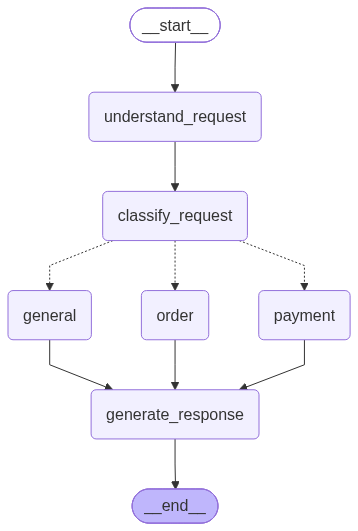

In [12]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
#Run the graph

result=app.

In [2]:
#The format to store the chat history

import os
from getpass import getpass
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage,AIMessage

if "OPENAI_API_KEY" not in os.environ:
    os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key:")

messages=[HumanMessage(content=("My payment was deducted but my order is still pending.")),
         AIMessage(content=("I'll help you check your payment and order status.")),
         HumanMessage(content=("My order id is ORD12345"))]

print("====Message History====")

for message in messages:
    print("TYPE:",type(message).__name__)
    print("CONTENT:",message.content)
    print("---------------------------------")

Enter your OpenAI API key: ········


====Message History====
TYPE: HumanMessage
CONTENT: My payment was deducted but my order is still pending.
---------------------------------
TYPE: AIMessage
CONTENT: I'll help you check your payment and order status.
---------------------------------
TYPE: HumanMessage
CONTENT: My order id is ORD12345
---------------------------------


In [6]:
llm=ChatOpenAI(model="gpt-4o-mini")
response=llm.invoke(messages)
print(response.content)
messages.append(response)

I don't have access to specific order details or payment systems. I recommend checking the order status on the website where you made the purchase or contacting their customer support. They will be able to provide you with the most accurate information regarding your order and payment.


In [7]:
print(messages)

[HumanMessage(content='My payment was deducted but my order is still pending.', additional_kwargs={}, response_metadata={}), AIMessage(content="I'll help you check your payment and order status.", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='My order id is ORD12345', additional_kwargs={}, response_metadata={}), AIMessage(content="I don't have access to specific order details or payment systems. I recommend checking the order status on the website where you made the purchase or contacting their customer support. They will be able to provide you with the most accurate information regarding your order and payment.", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 43, 'total_tokens': 93, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_detail

In [9]:
#Initializing chat model

model = ChatOpenAI(model="gpt-4o-mini",temperature=0)
response=model.invoke(messages)

print("\n======================AI RESPONSE==================")

print("Type:",type(response).__name__)
print("\nCONTENT:")
print(response.content)

#display response METADATA
print("\n=============RESPONSE METADATA==============")
print(response.response_metadata)

#Display token usage
print("\n============TOKEN USAGE=================")
print(response.usage_metadata)


======================AI RESPONSE==================
Type: AIMessage

CONTENT:
I don't have access to specific order details or payment systems. I recommend checking the order status on the website where you made the purchase or contacting their customer support. They will be able to provide you with the most accurate information regarding your order and payment.

=============RESPONSE METADATA==============
{'token_usage': {'completion_tokens': 50, 'prompt_tokens': 97, 'total_tokens': 147, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_0e7150ae59', 'id': 'chatcmpl-Eab3JuEIvCzV4ghG353kR9CtBfunV', 'service_tier': 'default', 'finish_reason': 'stop',

In [10]:
#building a tool calling llm  using langgraph

import os
from getpass import getpass
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage,AIMessage
from langchain_core.tools import tool

if "OPENAI_API_KEY" not in os.environ:
    os.environ["OPENAI_API_KEY"]=getpass("Enter your OpenAI API key:")

@tool
def check_payment_status(order_id: str) -> str:
    """
    Check the payment status for a customer order.
    
    Args:
    order_id: Customer order ID.
    """

    if order_id=="ORD12345":
        return "order is currently pending"
    return "Order information not found."  

#tool
def check_order_status(order_id: str) -> str:
    """
    Check the current order status.
    
    Args:
    order_id= customer order ID"""

    if order_id == "ORD12345":
        return "Order is currently pending."
    return "Order information not found"

@tool
def create_support_ticket(issue: str) -> str:
    """
    Create a support ticket for a custmer issue.
    
    Args:
    issue:Description of the issue.
    """

    return f("Support ticket raised for {issue}.")


tools=[check_payment_status,check_order_status,create_support_ticket]

In [11]:
#Initialize the model

model = ChatOpenAI(model="gpt-4o-mini",temperature=0)

#Bind tools
model_with_tools=model.bind_tools(tools)

#USer question
messages =[HumanMessage(content=("My payment was deducted."
                                "But my order is still pending."
                                "My order ID is ORD12345."
                                "Please check my payment status."))]

response=model_with_tools.invoke(messages)

print(response)

print(response.content)
print(response.tool_calls)

content='' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 18, 'prompt_tokens': 136, 'total_tokens': 154, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_8421a6e076', 'id': 'chatcmpl-EabMqHF2XzQ96nVxY8YqxAH6jOtLd', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None} id='lc_run--01a152e5-c642-75a1-98b8-99bb73462486-0' tool_calls=[{'name': 'check_payment_status', 'args': {'order_id': 'ORD12345'}, 'id': 'call_k7YT2MyfYBGMMmhsq4vYdsV9', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 136, 'output_tokens': 18, 'total_tokens': 154, 'input_token_details': {'aud

In [12]:
#Simple router agent using langgraph
!pip install -q -U langchain-openai langgraph


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import os
from getpass import getpass
from typing import TypedDict
from typing_extensions import Annotated
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import AnyMessage,HumanMessage
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode,tools_condition

In [15]:
if "OPENAI_API_KEY" not in os.environ:
    os.environ["OPENAI_API_KEY"]=getpass("Enter your OpenAI API Key:")

In [16]:
class SupportState(TypedDict):
    messages: Annotated[list[AnyMessage],add_messages]
@tool
def check_payment_status(order_id: str) -> str:
    """
    Check the payment status for a customer order.
    Args:
        order_id: Customer order ID.
    """
    if order_id == "ORD12345":
        return ("Payment successful.")

    return ("Payment information not found.")

@tool
def check_order_status(order_id: str) -> str:
    """
    Check the current order status.
    Args:
        order_id:Customer order ID.
    """
    if order_id == "ORD12345":
        return ("Order is currently pending.")

    return ("Order information not found.")


@tool
def create_support_ticket(issue: str) -> str:
    """
    Create a support ticket for a customer issue.

    Args:
       issue:Description of the issue.
    """
    return (f"Support ticket created for: {issue}")

tools = [check_payment_status,check_order_status,create_support_ticket]

In [17]:
#Initialize chat model
model=ChatOpenAI(model="gpt-4o-mini",temperature=0)

#Bind tools
model_with_tools=model.bind_tools(tools)

In [19]:
#Create agent Node
def agent_node(state: SupportState):
    print("\nAgent Node")
    response=model_with_tools.invoke(state["messages"])
    return {"messages":[response]}

#Create tool node
tool_node=ToolNode(tools)

In [20]:
#create state graph

graph=StateGraph(SupportState)

graph.add_node("agent",agent_node)
graph.add_node("tools",tool_node)

graph.add_edge(START,"agent")

#conditional router
graph.add_conditional_edges("agent",tools_condition,{"tools":"tools",END:END})

graph.add_edge("tools","agent")

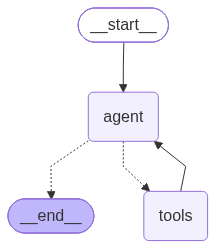

In [22]:
app = graph.compile()

from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [23]:
# RUN AGENT
result = app.invoke({"messages": [HumanMessage(content=("My payment was deducted "
                                                        "but my order is still pending. "
                                                        "My order ID is ORD12345."))]})
result


Agent Node

Agent Node


{'messages': [HumanMessage(content='My payment was deducted but my order is still pending. My order ID is ORD12345.', additional_kwargs={}, response_metadata={}, id='380a6603-a932-414a-92d8-ffa4dfb67fee'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 52, 'prompt_tokens': 140, 'total_tokens': 192, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_d3b38c8dc1', 'id': 'chatcmpl-EabzpXKnONpRHnsdaSRmnJ8GIveDD', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1530a-a5ee-71e0-aaca-b18a4caee255-0', tool_calls=[{'name': 'check_payment_status', 'a

In [24]:
# DISPLAY CONVERSATION
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

My payment was deducted but my order is still pending. My order ID is ORD12345.
================================== Ai Message ==================================
Tool Calls:
  check_payment_status (call_spnPwJD3m6LBJfeJAhaSap6c)
 Call ID: call_spnPwJD3m6LBJfeJAhaSap6c
  Args:
    order_id: ORD12345
  check_order_status (call_zbYx4mkdGUOGK1yblay65itC)
 Call ID: call_zbYx4mkdGUOGK1yblay65itC
  Args:
    order_id: ORD12345
================================= Tool Message =================================
Name: check_payment_status

Payment successful.
================================= Tool Message =================================
Name: check_order_status

Order is currently pending.
================================== Ai Message ==================================

Your payment has been successfully processed, but your order is currently pending. If you need further assistance or have any concerns, please let me